# LGMMA-X | Phase 5G — Notebook 02

## Exploratory chronological-block comparisons and paired tests

> **Status:** Verified frozen-inference analysis. This is a corrected research copy, not a training notebook.

**Workflow:** Frozen hashes → baseline preflight → alignment → block metrics → paired tests → Figure IV-4 / Table IV-14

**Source safety:** No autoencoder training, GMM refitting, or rewriting of archived checkpoints. The notebooks deliberately stop when artifacts are missing or inconsistent.

---

**November 23 replay:** uses `20261123T024650` and writes only to `reproduction/phase5g_final_results_20261123/`. Frozen source integrity checks remain active. These are candidates until baseline provenance checks and notebook execution pass.


### 1. Imports and repository configuration

Locate the repository automatically from its root or `notebooks/` directory. All generated files are written under `reproduction/phase5g_final_results/`.

In [ ]:
from pathlib import Path

import hashlib, json

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score, average_precision_score

def repo_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / 'src/modeling/data/evaluation/test_proxy_labels.csv').exists() and (candidate / 'reproduction').is_dir():
            return candidate.resolve()
    raise FileNotFoundError('Run from the thesis repository or its notebooks/ subdirectory')

ROOT = repo_root()

OUT = ROOT / 'reproduction/phase5g_final_results_20261123'

OUT.mkdir(parents=True, exist_ok=True)

REPLAY = ROOT / 'reproduction/verified_dag_runs/20261123T024650/replay'

LABELS = ROOT / 'src/modeling/data/evaluation/test_proxy_labels.csv'

META = ROOT / 'src/modeling/data/sequence_metadata/test_sequence_metadata.parquet'

HELDOUT = ROOT / 'reproduction/heldout_evaluation/reproduced_test_scores.csv'

THRESHOLD = ROOT / 'reproduction/gmm_calibration/selected_threshold.txt'

EXPECTED = {LABELS: '0c71225d0d4af73599c23555e6d093987ac459ed74b19ff78e8b40d51e422f8c', META: '508f830b4056f1f0084dc1fec594651dda0293dd7af017116907b779a580a7ad', REPLAY / 'test_predictions.npy': 'cea82f3bf6d5e5312871e960bde4b5ac69e62d23a5bc83ea83ff97f8e59a8f68', REPLAY / 'test_anomaly_scores.npy': '38d087fd00ceb37547899886817ccecec3a257f793a718ae24e6bb89191ec460', REPLAY / 'test_reconstruction_errors.npy': '6184101ff0a55d259c6082543f1a875806a504363ef0980bc433e6c371f50177', THRESHOLD: '532dd182b3253f13af4a9743b391c734991db58969f67ea27d6b94d63ce04270'}


### 2. Frozen-artifact integrity gate

Compare source files against their known SHA-256 digests. A mismatch stops execution before any analysis.

In [ ]:
def digest(p):
    h = hashlib.sha256()
    with p.open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

for path, known in EXPECTED.items():
    if not path.is_file():
        raise FileNotFoundError(str(path))
    actual = digest(path)
    if actual != known:
        raise ValueError(f'Frozen artifact changed: {path}\n{actual} != {known}')

print('[PASS] 7 frozen input hashes. Root:', ROOT)


[PASS] 7 frozen input hashes. Root: C:\Users\Kyle Eva\Downloads\datasci2-thesis


### 3. Sequence and inference alignment

Verify sequence IDs, segments, timestamps, proxy criteria, scores, labels, and predictions against the held-out evaluation.

In [ ]:
labels = pd.read_csv(LABELS).sort_values('sequence_id').reset_index(drop=True)

meta = pd.read_parquet(META).sort_values('sequence_id').reset_index(drop=True)

ids = labels.sequence_id.to_numpy(dtype=int)

if not (len(ids) == 21749 and np.array_equal(ids, np.arange(21749))):
    raise ValueError('Sequence IDs are not 0..21748')

if not np.array_equal(meta.sequence_id.to_numpy(), ids):
    raise ValueError('Metadata ID mismatch')

if not np.array_equal(meta.segment_id.to_numpy(), labels.segment_id.to_numpy()):
    raise ValueError('Segment ID mismatch')

for key in ('start_timestamp', 'end_timestamp'):
    a = pd.to_datetime(meta[key], utc=True).to_numpy()
    b = pd.to_datetime(labels[key], utc=True).to_numpy()
    if not np.array_equal(a, b):
        raise ValueError(f'Metadata timestamp mismatch: {key}')

y = labels.proxy_anomaly.to_numpy(dtype=np.int8)

criteria = ['extreme_return', 'range_expansion', 'volatility_burst', 'flash_movement']

if not np.array_equal(y, (labels[criteria].to_numpy().sum(axis=1) > 0).astype(np.int8)):
    raise ValueError('Proxy labels do not match OR of criteria')

scores = np.load(REPLAY / 'test_anomaly_scores.npy', allow_pickle=False)

pred = np.load(REPLAY / 'test_predictions.npy', allow_pickle=False)

mae = np.load(REPLAY / 'test_reconstruction_errors.npy', allow_pickle=False)

cutoff = float(THRESHOLD.read_text().strip())

if any((len(a) != 21749 for a in (scores, pred, mae))):
    raise ValueError('Output length mismatch')

if not np.array_equal(pred, (scores >= cutoff).astype(np.int8)):
    raise ValueError('GMM threshold mismatch')

prior = pd.read_csv(HELDOUT).sort_values('sequence_id').reset_index(drop=True)

if not np.array_equal(prior.sequence_id.to_numpy(), ids):
    raise ValueError('Heldout sequence ID mismatch')

if not np.array_equal(prior.proxy_anomaly.to_numpy(), y):
    raise ValueError('Heldout label mismatch')

if not np.array_equal(prior.predicted_anomaly.to_numpy(), pred):
    raise ValueError('Heldout prediction mismatch')

if not np.allclose(prior.anomaly_score.to_numpy(), scores, atol=1e-10, rtol=0):
    raise ValueError('Heldout score mismatch')

if not np.allclose(prior.reconstruction_error.to_numpy(), mae, atol=1e-06, rtol=0):
    raise ValueError('Heldout MAE mismatch')

assert tuple(confusion_matrix(y, pred, labels=[0, 1]).ravel()) == (3422, 498, 3713, 14116)

base = labels[['sequence_id', 'segment_id', 'start_timestamp', 'end_timestamp', 'proxy_anomaly']].copy()

base['start_timestamp'] = pd.to_datetime(base.start_timestamp, utc=True)

base['end_timestamp'] = pd.to_datetime(base.end_timestamp, utc=True)

print('[PASS] aligned 21,749 sequences; TP=14116, TN=3422, FP=498, FN=3713; threshold', cutoff)


[PASS] aligned 21,749 sequences; TP=14116, TN=3422, FP=498, FN=3713; threshold -0.27292780574931297


### 4. Metric helper

Use the same standard classification and ranking metrics throughout both notebooks.

In [ ]:
def rates(true, prediction, values):
    t = true.to_numpy() if isinstance(true, pd.Series) else np.asarray(true)
    p = prediction.to_numpy() if isinstance(prediction, pd.Series) else np.asarray(prediction)
    s = values.to_numpy() if isinstance(values, pd.Series) else np.asarray(values)
    result = {'precision': precision_score(t, p, zero_division=0), 'recall': recall_score(t, p, zero_division=0), 'f1': f1_score(t, p, zero_division=0), 'balanced_accuracy': balanced_accuracy_score(t, p), 'roc_auc': roc_auc_score(t, s), 'average_precision': average_precision_score(t, s)}
    return result


## 5. Preflight — required per-sequence baseline outputs

Check for seven aligned score sources. If the Phase 5E.3 baseline replay exports are absent, stop safely and list exactly which files are missing.

---

In [ ]:
SCORE_DIR = OUT / 'aligned_score_sources'
SOURCES = {'LGMMA-X': 'lgmma_verified.csv', 'ARIMA-GARCH': 'arima_garch_verified.csv', 'Z-score': 'zscore_replayed.csv', 'Isolation Forest': 'isolation_forest_replayed.csv', 'One-Class SVM': 'one_class_svm_replayed.csv', 'LSTM-AE (Fixed Threshold)': 'lstm_fixed_candidate.csv', 'LSTM-AE (Raw Error Ranking)': 'lstm_raw_error_verified.csv'}
missing = [(name, SCORE_DIR / file) for name, file in SOURCES.items() if not (SCORE_DIR / file).is_file()]
if missing:
    print('MISSING INPUTS:')
    for name, path in missing:
        print(' -', name, ':', path)
    print('The missing replayed baseline files must be generated from the saved Phase 5E.3 models, not from aggregate reports.')
    print('Columns: sequence_id, segment_id, start_timestamp, end_timestamp, proxy_anomaly, anomaly_score, prediction')
    raise FileNotFoundError('Cannot compute Figure IV-4 / Table IV-14 until all per-sequence baseline inputs exist')
print('[PASS] all seven model input files exist')


[PASS] all seven model input files exist


## 6. Cross-model alignment and aggregate metric checks

Verify IDs, timestamps, segments, labels, scoring direction, and agreement with the reconciled aggregate baseline results before computing statistics.

---

In [ ]:
from scipy.stats import shapiro, wilcoxon, ttest_1samp
from statsmodels.stats.multitest import multipletests
raw = {}
for name, file in SOURCES.items():
    t = pd.read_csv(SCORE_DIR / file)
    required = {'sequence_id', 'segment_id', 'start_timestamp', 'end_timestamp', 'proxy_anomaly', 'anomaly_score'}
    if name != 'LSTM-AE (Raw Error Ranking)':
        required.add('prediction')
    if not required.issubset(t.columns):
        raise ValueError(f'{name}: missing columns {sorted(required - set(t.columns))}')
    t = t.sort_values('sequence_id').reset_index(drop=True)
    if not (len(t) == 21749 and t.sequence_id.is_unique and np.array_equal(t.sequence_id.to_numpy(), ids)):
        raise ValueError(f'{name}: IDs or length mismatch')
    for field in ('segment_id', 'proxy_anomaly'):
        if not np.array_equal(t[field].to_numpy(), base[field].to_numpy()):
            raise ValueError(f'{name}: {field} mismatch')
    for field in ('start_timestamp', 'end_timestamp'):
        if not np.array_equal(pd.to_datetime(t[field], utc=True).to_numpy(), base[field].to_numpy()):
            raise ValueError(f'{name}: {field} mismatch')
    if not np.isfinite(t.anomaly_score.to_numpy()).all():
        raise ValueError(f'{name}: nonfinite scores')
    if name != 'LSTM-AE (Raw Error Ranking)' and (not t.prediction.isin([0, 1]).all()):
        raise ValueError(f'{name}: invalid predictions')
    raw[name] = t
if not np.allclose(raw['LGMMA-X'].anomaly_score.to_numpy(), scores, atol=1e-12, rtol=0):
    raise ValueError('LGMMA score mismatch')
if not np.array_equal(raw['LGMMA-X'].prediction.to_numpy(), pred):
    raise ValueError('LGMMA prediction mismatch')
for key in ('LSTM-AE (Fixed Threshold)', 'LSTM-AE (Raw Error Ranking)'):
    if not np.allclose(raw[key].anomaly_score.to_numpy(), mae, rtol=0, atol=1e-07):
        raise ValueError(key + ' MAE mismatch')
if not np.array_equal(raw['LSTM-AE (Fixed Threshold)'].prediction.to_numpy(), pred):
    raise ValueError('Provisional fixed-MAE classifications differ from GMM')
recon = pd.read_csv(ROOT / 'reproduction/phase5g_chapter4_reconciliation/table_IV13_candidate_seven_models.csv')
for model in ('Z-score', 'Isolation Forest', 'One-Class SVM', 'ARIMA-GARCH'):
    r = recon.loc[recon.model == model]
    if len(r) != 1:
        raise ValueError('Aggregate verification row missing for ' + model)
    t = raw[model]
    actual = rates(y, t.prediction.to_numpy(), t.anomaly_score.to_numpy())
    expected = r.iloc[0]
    for metric in ('precision', 'recall', 'f1', 'balanced_accuracy', 'roc_auc', 'average_precision'):
        if abs(actual[metric] - float(expected[metric])) > 1e-06:
            raise ValueError(f'{model} score output does not agree with previously verified aggregate {metric}: {actual[metric]} vs {expected[metric]}')
print('[PASS] 21,749 IDs, four metadata keys, labels and six baseline aggregate metrics validated')


[PASS] 21,749 IDs, four metadata keys, labels and six baseline aggregate metrics validated


## 7. Ten common chronological evaluation blocks

Sort by test-sequence time, create ten approximately equal blocks, and calculate applicable classification and ranking metrics within each block.

---

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score, average_precision_score
ordered = base.sort_values(['start_timestamp', 'sequence_id']).sequence_id.to_numpy()
block_of_id = np.empty(21749, dtype=int)
block_of_id[ordered] = np.arange(21749) * 10 // 21749 + 1
records = []
for model, t in raw.items():
    for block in range(1, 11):
        ix = np.where(block_of_id == block)[0]
        truth = y[ix]
        ss = t.anomaly_score.to_numpy()[ix]
        row = {'model': model, 'evaluation_block': block, 'n_sequences': len(ix), 'n_proxy_positive': int(truth.sum()), 'n_proxy_normal': int((truth == 0).sum())}
        if model != 'LSTM-AE (Raw Error Ranking)':
            pp = t.prediction.to_numpy(dtype=int)[ix]
            row.update({'precision': precision_score(truth, pp, zero_division=0), 'recall': recall_score(truth, pp, zero_division=0), 'f1': f1_score(truth, pp, zero_division=0), 'balanced_accuracy': balanced_accuracy_score(truth, pp) if len(np.unique(truth)) == 2 else np.nan})
        else:
            row.update({k: np.nan for k in ('precision', 'recall', 'f1', 'balanced_accuracy')})
        row['roc_auc'] = roc_auc_score(truth, ss) if len(np.unique(truth)) == 2 else np.nan
        row['average_precision'] = average_precision_score(truth, ss) if len(np.unique(truth)) == 2 else np.nan
        records.append(row)
blocks = pd.DataFrame(records)
blocks.to_csv(OUT / 'table_IV14_block_metrics.csv', index=False)
print(blocks.groupby('model').size())
display(blocks.head())


model
ARIMA-GARCH                    10
Isolation Forest               10
LGMMA-X                        10
LSTM-AE (Fixed Threshold)      10
LSTM-AE (Raw Error Ranking)    10
One-Class SVM                  10
Z-score                        10
dtype: int64


,model,evaluation_block,n_sequences,n_proxy_positive,n_proxy_normal,precision,recall,f1,balanced_accuracy,roc_auc,average_precision
0,LGMMA-X,1,2175,1892,283,0.991309,0.904334,0.945826,0.925665,0.967316,0.995310
1,LGMMA-X,2,2175,1802,373,0.983491,0.694229,0.813923,0.818964,0.920244,0.983518
2,LGMMA-X,3,2175,1844,331,0.964263,0.834056,0.894446,0.830925,0.909100,0.983581
3,LGMMA-X,4,2175,1742,433,0.947925,0.721010,0.819041,0.780828,0.905928,0.973681
4,LGMMA-X,5,2175,1875,300,0.979042,0.872000,0.922426,0.877667,0.950663,0.992163


## 8. Paired block-level differences

Calculate LGMMA-X minus baseline performance for each eligible model, metric, and chronological block.

---

In [ ]:
metrics = ['precision', 'recall', 'f1', 'balanced_accuracy', 'roc_auc', 'average_precision']
comparison = []
for model in list(SOURCES)[1:]:
    for metric in metrics:
        if model == 'LSTM-AE (Raw Error Ranking)' and metric not in ('roc_auc', 'average_precision'):
            continue
        left = blocks.loc[blocks.model == 'LGMMA-X', ['evaluation_block', metric]].rename(columns={metric: 'lgmma'})
        right = blocks.loc[blocks.model == model, ['evaluation_block', metric]].rename(columns={metric: 'baseline'})
        merged = left.merge(right, on='evaluation_block', validate='one_to_one').dropna()
        for r in merged.itertuples(index=False):
            comparison.append({'baseline_model': model, 'metric': metric, 'evaluation_block': int(r.evaluation_block), 'lgmma': float(r.lgmma), 'baseline': float(r.baseline), 'difference': float(r.lgmma - r.baseline)})
differences = pd.DataFrame(comparison)
differences.to_csv(OUT / 'figure_IV4_paired_block_differences.csv', index=False)
print('Eligible model–metric comparisons:', differences.groupby(['baseline_model', 'metric']).ngroups)


Eligible model–metric comparisons: 32


## 9. Exploratory paired tests with Holm correction

Handle all-zero differences before normality diagnostics. Apply the historical paired-test rule and Holm-adjust p-values within each metric family. **Do not interpret these p-values as confirmatory evidence.**

---

In [ ]:
def test_one(d):
    d = np.asarray(d, dtype=float)
    if len(d) < 3:
        return dict(test='insufficient_data', shapiro_p=np.nan, statistic=np.nan, p_value=np.nan)
    if np.all(d == 0):
        return dict(test='all_zero', shapiro_p=np.nan, statistic=0, p_value=1.0)
    if np.isclose(d.std(), 0, rtol=0, atol=1e-14):
        return dict(test='near_constant_nonzero', shapiro_p=np.nan, statistic=np.nan, p_value=np.nan)
    sp = float(shapiro(d).pvalue)
    if sp >= 0.05:
        q = ttest_1samp(d, 0)
        return dict(test='paired_t_test', shapiro_p=sp, statistic=float(q.statistic), p_value=float(q.pvalue))
    q = wilcoxon(d, alternative='two-sided', zero_method='wilcox')
    return dict(test='wilcoxon_signed_rank', shapiro_p=sp, statistic=float(q.statistic), p_value=float(q.pvalue))
rows = []
for (model, metric), g in differences.groupby(['baseline_model', 'metric']):
    d = g.difference.to_numpy()
    r = test_one(d)
    rows.append({'baseline_model': model, 'metric': metric, 'n_blocks': len(d), 'mean_difference': float(d.mean()), 'median_difference': float(np.median(d)), 'provisional_fixed_cutoff': model == 'LSTM-AE (Fixed Threshold)', **r})
tests = pd.DataFrame(rows)
tests['holm_adjusted_p'] = np.nan
tests['holm_reject_0_05'] = False
for metric, g in tests.groupby('metric'):
    ix = g.index[g.p_value.notna()]
    if len(ix):
        reject, adj, _, _ = multipletests(tests.loc[ix, 'p_value'].to_numpy(), alpha=0.05, method='holm')
        tests.loc[ix, 'holm_adjusted_p'] = adj
        tests.loc[ix, 'holm_reject_0_05'] = reject
tests['direction'] = np.where(tests.mean_difference > 0, 'LGMMA-X', np.where(tests.mean_difference < 0, 'Baseline', 'Tie'))
tests['evidence_status'] = np.where(tests.provisional_fixed_cutoff, 'EXPLORATORY_PROVISIONAL_CALIBRATION', 'EXPLORATORY_SINGLE_PERIOD_TEMPORAL_DEPENDENCE')
tests.to_csv(OUT / 'table_IV14_exploratory_all_comparisons.csv', index=False)
display(tests.sort_values(['metric', 'holm_adjusted_p']))
print('Exploratory Holm rejections:', int(tests.holm_reject_0_05.sum()), 'out of', len(tests), 'eligible tests.')
print('Do NOT report as independent or confirmatory significance.')


,baseline_model,metric,n_blocks,mean_difference,median_difference,provisional_fixed_cutoff,test,shapiro_p,statistic,p_value,holm_adjusted_p,holm_reject_0_05,direction,evidence_status
0,ARIMA-GARCH,average_precision,10,0.016643,0.017358,False,paired_t_test,5.334525e-01,4.904893,8.419473e-04,5.051684e-03,True,LGMMA-X,EXPLORATORY_SINGLE_PERIOD_TEMPORAL_DEPENDENCE
26,Z-score,average_precision,10,0.007749,0.003603,False,wilcoxon_signed_rank,1.960193e-03,0.000000,1.953125e-03,9.765625e-03,True,LGMMA-X,EXPLORATORY_SINGLE_PERIOD_TEMPORAL_DEPENDENCE
6,Isolation Forest,average_precision,10,-0.004310,-0.003165,False,paired_t_test,2.468258e-01,-3.580846,5.922911e-03,2.369164e-02,True,Baseline,EXPLORATORY_SINGLE_PERIOD_TEMPORAL_DEPENDENCE
20,One-Class SVM,average_precision,10,0.006073,0.002425,False,paired_t_test,2.898811e-01,1.767109,1.110115e-01,3.330345e-01,False,LGMMA-X,EXPLORATORY_SINGLE_PERIOD_TEMPORAL_DEPENDENCE
12,LSTM-AE (Fixed Threshold),average_precision,10,-0.000003,0.000000,True,wilcoxon_signed_rank,1.003693e-07,0.000000,1.000000e+00,1.000000e+00,False,Baseline,EXPLORATORY_PROVISIONAL_CALIBRATION
18,LSTM-AE (Raw Error Ranking),average_precision,10,-0.000003,0.000000,False,wilcoxon_signed_rank,1.003693e-07,0.000000,1.000000e+00,1.000000e+00,False,Baseline,EXPLORATORY_SINGLE_PERIOD_TEMPORAL_DEPENDENCE
1,ARIMA-GARCH,balanced_accuracy,10,0.063672,0.069467,False,paired_t_test,9.836426e-01,5.022876,7.162791e-04,3.581395e-03,True,LGMMA-X,EXPLORATORY_SINGLE_PERIOD_TEMPORAL_DEPENDENCE
27,Z-score,balanced_accuracy,10,0.103282,0.100625,False,paired_t_test,6.998860e-01,4.941504,8.005840e-04,3.581395e-03,True,LGMMA-X,EXPLORATORY_SINGLE_PERIOD_TEMPORAL_DEPENDENCE
7,Isolation Forest,balanced_accuracy,10,-0.019805,-0.015517,False,paired_t_test,2.354773e-01,-1.835744,9.958291e-02,2.987487e-01,False,Baseline,EXPLORATORY_SINGLE_PERIOD_TEMPORAL_DEPENDENCE
13,LSTM-AE (Fixed Threshold),balanced_accuracy,10,0.000000,0.000000,True,all_zero,NaN,0.000000,1.000000e+00,1.000000e+00,False,Tie,EXPLORATORY_PROVISIONAL_CALIBRATION


Exploratory Holm rejections: 18 out of 32 eligible tests.
Do NOT report as independent or confirmatory significance.


## 10. Figure IV-4 — corrected blockwise differences

Create the revised exploratory boxplot from calculated paired differences and save a PNG.

---

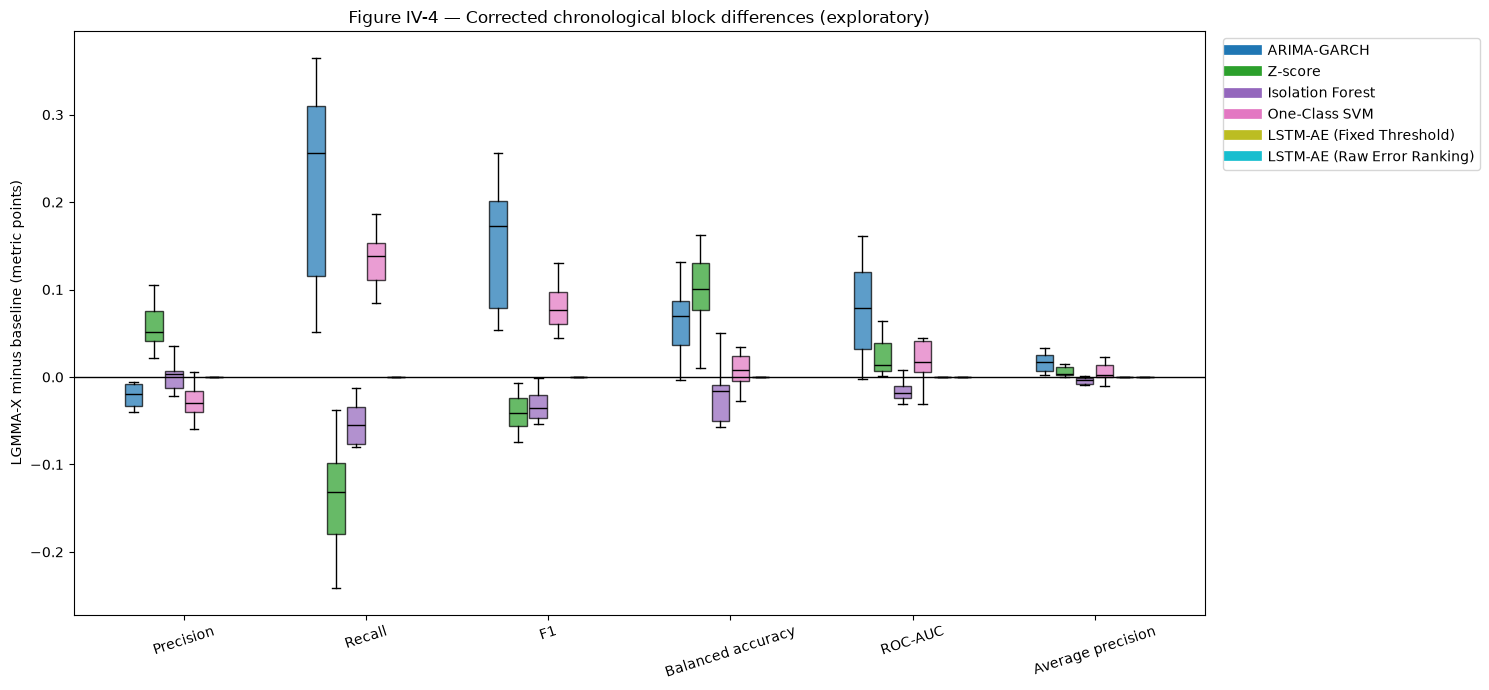

Saved: C:\Users\Kyle Eva\Downloads\datasci2-thesis\reproduction\phase5g_final_results\figure_IV4_corrected_block_differences.png


In [ ]:
fig, ax = plt.subplots(figsize=(15, 7))
names = list(differences.baseline_model.unique())
ms = metrics
palette = plt.cm.tab10(np.linspace(0, 1, len(names)))
width = 0.11
for j, name in enumerate(names):
    pos = []
    values = []
    for i, metric in enumerate(ms):
        d = differences.loc[(differences.baseline_model == name) & (differences.metric == metric), 'difference'].to_numpy()
        if len(d):
            pos.append(i + (j - (len(names) - 1) / 2) * width)
            values.append(d)
    if values:
        parts = ax.boxplot(values, positions=pos, widths=width * 0.87, patch_artist=True, showfliers=False, manage_ticks=False)
        for patch in parts['boxes']:
            patch.set_facecolor(palette[j])
            patch.set_alpha(0.72)
        for item in parts['medians']:
            item.set_color('black')
        ax.plot([], [], color=palette[j], linewidth=7, label=name)
ax.set_xticks(np.arange(len(ms)), ['Precision', 'Recall', 'F1', 'Balanced accuracy', 'ROC-AUC', 'Average precision'], rotation=18)
ax.axhline(0, color='black', lw=1)
ax.set_ylabel('LGMMA-X minus baseline (metric points)')
ax.set_title('Figure IV-4 — Corrected chronological block differences (exploratory)')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(OUT / 'figure_IV4_corrected_block_differences.png', dpi=220, bbox_inches='tight')
plt.show()
print('Saved:', OUT / 'figure_IV4_corrected_block_differences.png')


## 11. Verification status and manuscript caution

Export the evidence-status JSON documenting the provisional fixed-MAE cutoff and temporal-dependence limitations.

---

In [ ]:
status = {'status': 'EXPLORATORY_NOT_CONFIRMATORY', 'test_sequences': 21749, 'blocks': 10, 'tests': len(tests), 'holm_rejections': int(tests.holm_reject_0_05.sum()), 'fixed_mae_threshold_provenance': 'NOT_FULLY_CONFIRMED', 'temporal_independence': 'NOT_ESTABLISHED', 'note': 'Do not reuse archived Figure IV-4 / Table IV-14 values; this is an exploratory comparison from frozen scores, not independent experimental replication.'}
(OUT / 'statistical_comparison_status.json').write_text(json.dumps(status, indent=2))
print(json.dumps(status, indent=2))


{
  "status": "EXPLORATORY_NOT_CONFIRMATORY",
  "test_sequences": 21749,
  "blocks": 10,
  "tests": 32,
  "holm_rejections": 18,
  "fixed_mae_threshold_provenance": "NOT_FULLY_CONFIRMED",
  "temporal_independence": "NOT_ESTABLISHED",
  "note": "Do not reuse archived Figure IV-4 / Table IV-14 values; this is an exploratory comparison from frozen scores, not independent experimental replication."
}
